# Algoritmo de Inferencia Híbrida basado en Ensamble Random Forest y Reglas Clínicas para la Detección y Clasificación de la Ansiedad Digital en Poblaciones Académicas de Alta Hiperconectividad (SERANA)
**Autores:** Sebastian Andre Nuñez Alvarez y Darwin Karl Salazar Gutiérrez  
**Filiación:** Universidad Peruana de Ciencias Aplicadas (UPC), Lima, Perú  
**Dataset:** *Digital Sedentary Behavior, Mobile Device Dependence, Musculoskeletal Symptoms, and Mental Health among University Students* (Versión 2, $N = 1,220$ estudiantes universitarios; Giraldo-Jimenez et al., 2026, `doi: 10.17632/k6pwtndj44.2`).

## 1. Carga de Librerías y Montaje de Google Drive (Secciones II.A y II.B)

In [1]:
import os
import io
import zlib
import base64
import pickle
import warnings
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, precision_score, recall_score
)
import plotly.express as px
import plotly.graph_objects as go
warnings.filterwarnings('ignore')

print('Librerías para el motor ML híbrido de SERANA cargadas correctamente.')

Librerías para el motor ML híbrido de SERANA cargadas correctamente.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# 1. Cargar dataset real (compatible localmente y en Google Colab)
import os
import pandas as pd

posibles_rutas = [
    'dataset_tmd_stai.csv',
    '../dataset_tmd_stai.csv',
    '/content/drive/MyDrive/20262/Digital Sedentary Behavior, Mobile Device Dependen/Dataset_MobileDependence_MusculoskeletalSymptoms_Depression_Anxiety-zTaMsO.csv',
    'Dataset_MobileDependence_MusculoskeletalSymptoms_Depression_Anxiety-zTaMsO.csv'
]
csv_path = None
for p in posibles_rutas:
    if os.path.exists(p):
        csv_path = p
        break

if csv_path is None:
    csv_path = posibles_rutas[2]

df = pd.read_csv(csv_path)
print(f'Dataset cargado exitosamente desde: {csv_path} | Dimensiones: {df.shape}')


Index(['Code', 'Program', 'Department', 'Semester', 'Age', 'Sex', 'MS', 'SES',
       'Living_Arrangement', 'Family_Expression', 'Family_Activities',
       'Mobile_Use_Rules', 'Phone_Discrimination', 'Phone_Related_Arguments',
       'Residence_Area', 'Subscription_Plan', 'Network _Access', 'Areas_Use',
       'Time_First_Cellphone', 'Type_MD', 'Using_Text Messaging_Apps',
       'Using_Games_Apps', 'Using_social media_Apps', 'Using_Music_Apps',
       'Using_Videos_Apps', 'Using_Ttime-management_Apps', 'Using_Camara_Apps',
       'Using_Mail_Apps', 'Average_Time_Use', 'Hand_Dominance     ',
       'Body Position_Standing', 'Body Position_Walking ',
       'Body Position_Sitting on the Floor', 'Body Position_Sitting Supported',
       'Body Position_Sitting Unsupported',
       'Body Position_Lying on One's Side', 'Body Position_Lying Face Down',
       'Body Position_Lying Face Up', 'Usage time_Standing',
       'Usage time_Walking', 'Usage time_Sitting on the Floor',
       'Usage t

## 2. Vinculación Multi-Hoja (`TMD_data` + `Anxiety_data`), Corrección Psicométrica `STAI-Estado` (Ecuación 1) y 40 Predictores (Secciones II.C, II.D y II.E)
> **¿Por qué ocurría `IndexError: list index out of range`?**  
> Cuando se guarda un libro Excel (`.xlsx`) como `.csv` desde Excel, solo se exporta la primera hoja (`SocioDemo_data`, 49 columnas) y se pierden las hojas `TMD_data` (`Q1`..`Q22`) y `Anxiety_data` (`State_Anxiety item_1`..`item_20`).  
> La celda siguiente detecta automáticamente si `df` solo tiene las 49 columnas de `SocioDemo_data`, integra las hojas `TMD_data` y `Anxiety_data` vinculadas 1 a 1 por `Code` (incluso si el archivo `.xlsx` no está subido en Google Drive) y actualiza automáticamente tu `.csv` en Google Drive.

In [4]:
# Auto-vinculación de las hojas TMD_data (Q1..Q22) y Anxiety_data (State_Anxiety item_1..item_20)
# si el archivo CSV en Google Drive solo tenía las 49 columnas de la primera hoja (SocioDemo_data):
csv_drive_path  = '/content/drive/MyDrive/20262/Digital Sedentary Behavior, Mobile Device Dependen/Dataset_MobileDependence_MusculoskeletalSymptoms_Depression_Anxiety-zTaMsO.csv'
xlsx_drive_path = '/content/drive/MyDrive/20262/Digital Sedentary Behavior, Mobile Device Dependen/Dataset_MobileDependence_MusculoskeletalSymptoms_Depression_Anxiety-zTaMsO.xlsx'
_B64_TMD_STAI_SHEETS = '...'
if 'Q2' not in df.columns:
    if os.path.exists(xlsx_drive_path):
        xl = pd.ExcelFile(xlsx_drive_path)
        df_socio = xl.parse('SocioDemo_data')
        df_tmd   = xl.parse('TMD_data')
        df_anx   = xl.parse('Anxiety_data')
        tmd_new_cols = ['Code'] + [c for c in df_tmd.columns if c not in df_socio.columns]
        anx_new_cols = ['Code'] + [c for c in df_anx.columns if c not in df_socio.columns]
        df = df_socio.merge(df_tmd[tmd_new_cols], on='Code', how='inner').merge(df_anx[anx_new_cols], on='Code', how='inner')
    else:
        df_extra_sheets = pd.read_csv(io.BytesIO(zlib.decompress(base64.b64decode(_B64_TMD_STAI_SHEETS))))
        df = df.merge(df_extra_sheets, on='Code', how='inner')
    try:
        df.to_csv(csv_drive_path, index=False)
        print('CSV en Google Drive actualizado automáticamente con las hojas TMD_data y Anxiety_data vinculadas por Code.')
    except Exception:
        pass
# Verificación de integridad (Sección II.C)
assert len(df) == 1220 and df['Code'].is_unique, 'Se requieren exactamente 1,220 registros únicos por Code.'
# 1. Definición de la variable objetivo STAI-Estado con inversión de ítems positivos — Ecuación (1) (Sección II.D)
col_item1 = [c for c in df.columns if 'State_Anxiety' in c and 'item_1' in c][0]
state_raw_cols = [col_item1] + [f'item_{i}' for i in range(2, 21)]
df_stai_state = df[state_raw_cols].copy()
df_stai_state.columns = [f'STAI_S_{i}' for i in range(1, 21)]
# Invertir los 10 ítems positivos (1, 2, 5, 8, 10, 11, 15, 16, 19, 20): x_i* = 5 - x_i
ITEMS_POSITIVOS_STAI = [1, 2, 5, 8, 10, 11, 15, 16, 19, 20]
for i in ITEMS_POSITIVOS_STAI:
    df_stai_state[f'STAI_S_{i}'] = 5 - df_stai_state[f'STAI_S_{i}']
df['STAI_Estado_Puntaje_Corregido'] = df_stai_state.sum(axis=1)
# Categorías operativas: 0 = Bajo (20-37), 1 = Moderado (38-44), 2 = Alto (45-80)
df['risk_level'] = pd.cut(df['STAI_Estado_Puntaje_Corregido'], bins=[19, 37, 44, 80], labels=[0, 1, 2]).astype(int)
MAPA_ETIQUETAS = {0: 'Bajo (20-37)', 1: 'Moderado (38-44)', 2: 'Alto (45-80)'}
# 2. Selección de los 40 predictores (Sección II.E): 22 ítems TMD + 18 variables SocioDemo/Uso Digital
col_q1 = [c for c in df.columns if 'Q1' in c and 'Q10' not in c and 'Q11' not in c and 'Q12' not in c and 'Q13' not in c and 'Q14' not in c and 'Q15' not in c and 'Q16' not in c and 'Q17' not in c and 'Q18' not in c and 'Q19' not in c][0]
tmd_raw_cols = [col_q1] + [f'Q{i}' for i in range(2, 23)]
df_tmd_22 = df[tmd_raw_cols].copy()
TMD_COLS = [f'TMD_Q{i}' for i in range(1, 23)]
df_tmd_22.columns = TMD_COLS
SOCIO_18_COLS = [
    'Age', 'Semester', 'Sex',
    'Family_Expression', 'Family_Activities', 'Mobile_Use_Rules',
    'Phone_Discrimination', 'Phone_Related_Arguments',
    'Type_MD', 'Average_Time_Use',
    'Using_Text Messaging_Apps', 'Using_Games_Apps', 'Using_social media_Apps',
    'Using_Music_Apps', 'Using_Videos_Apps', 'Using_Ttime-management_Apps',
    'Using_Camara_Apps', 'Using_Mail_Apps'
]
X = pd.concat([df_tmd_22, df[SOCIO_18_COLS].copy()], axis=1)
y = df['risk_level'].copy()
# 3. Dividir en conjunto de desarrollo (80%, n=976) y prueba Hold-Out (20%, n=244) estratificado
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print('¡Preparación completada con éxito con el dataset real de 1,220 estudiantes!')
print(f' - Puntaje STAI-Estado sin invertir (Excel) : Media = {df["SUM_State_Anxiety"].mean():.2f}, Rango = [{df["SUM_State_Anxiety"].min()}, {df["SUM_State_Anxiety"].max()}]')
print(f' - Puntaje STAI-Estado corregido Eq. (1)    : Media = {df["STAI_Estado_Puntaje_Corregido"].mean():.2f}, Rango = [{df["STAI_Estado_Puntaje_Corregido"].min()}, {df["STAI_Estado_Puntaje_Corregido"].max()}]')
print(f' - Dimensiones Desarrollo (80%): {X_dev.shape}, Prueba Hold-Out (20%): {X_test.shape}')
print('\nDistribución de clases de STAI-Estado Corregido (risk_level):')
for k, v in y.value_counts().sort_index().items():
    print(f'  Clase {k} ({MAPA_ETIQUETAS[k]}): {v} estudiantes ({v/len(y)*100:.2f}%)')
# Alias de conveniencia para visualización
df['STAI_Estado_Total'] = df['STAI_Estado_Puntaje_Corregido']
df['Target_Categoria'] = df['risk_level']
df['TMD_Total_Calculado'] = X[TMD_COLS].sum(axis=1)


CSV en Google Drive actualizado automáticamente con las hojas TMD_data y Anxiety_data vinculadas por Code.
¡Preparación completada con éxito con el dataset real de 1,220 estudiantes!
 - Puntaje STAI-Estado sin invertir (Excel) : Media = 43.95, Rango = [20, 80]
 - Puntaje STAI-Estado corregido Eq. (1)    : Media = 39.24, Rango = [20, 71]
 - Dimensiones Desarrollo (80%): (976, 40), Prueba Hold-Out (20%): (244, 40)

Distribución de clases de STAI-Estado Corregido (risk_level):
  Clase 0 (Bajo (20-37)): 527 estudiantes (43.20%)
  Clase 1 (Moderado (38-44)): 268 estudiantes (21.97%)
  Clase 2 (Alto (45-80)): 425 estudiantes (34.84%)


## 3. Pipeline sin Fuga de Datos, Random Forest (`120` Árboles) y Capa de Reglas Experimentales (Secciones II.E y II.F)

In [5]:
NOMINAL_COLS = ['Sex', 'Type_MD']
NUMERIC_ORDINAL_COLS = [c for c in X.columns if c not in NOMINAL_COLS]

preprocessor = ColumnTransformer(
    transformers=[
        ('nominal', OneHotEncoder(handle_unknown='ignore', sparse_output=False), NOMINAL_COLS),
        ('num_ord', 'passthrough', NUMERIC_ORDINAL_COLS)
    ]
)

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=120,
        max_depth=12,
        min_samples_split=4,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

dummy_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])

def aplicar_capa_reglas_experimentales(X_df: pd.DataFrame, y_pred_rf: np.ndarray, proba_rf: np.ndarray):
    """
    Aplica la capa de reglas experimentales (Sección II.F) sobre las predicciones del Random Forest.
    Conserva la predicción original del RF, la predicción híbrida final y el motivo de cada modificación.
    """
    y_hibrido = np.array(y_pred_rf, copy=True)
    reglas_activadas = []

    tmd_sum      = X_df[TMD_COLS].sum(axis=1).values
    q3_conflicto = X_df['TMD_Q3'].values
    q16_control  = X_df['TMD_Q16'].values
    fam_exp      = X_df['Family_Expression'].values
    fam_act      = X_df['Family_Activities'].values
    avg_time     = X_df['Average_Time_Use'].values
    soc_apps     = X_df['Using_social media_Apps'].values

    for idx in range(len(X_df)):
        rf_c = int(y_pred_rf[idx])
        p_bajo, p_mod, p_alto = proba_rf[idx]
        p_max = proba_rf[idx, rf_c]
        regla = 'NINGUNA'

        # Regla 1: Sensibilización de Clase Moderada (1) en frontera de incertidumbre con alta exposición (>=3h/día)
        if rf_c != 1 and p_mod >= 0.32 and (p_max - p_mod) <= 0.045 and avg_time[idx] >= 3 and fam_act[idx] <= 3:
            y_hibrido[idx] = 1
            regla = 'R1_TRANSICION_MODERADA_ALTA_EXPOSICION'

        # Regla 2: Escalamiento a Clase Alta (2) por hiperconectividad, pérdida de control y baja cohesión familiar
        elif rf_c == 1 and p_alto >= 0.37 and avg_time[idx] >= 3 and soc_apps[idx] == 2 and (q3_conflicto[idx] >= 2 or q16_control[idx] >= 3) and fam_act[idx] <= 2:
            y_hibrido[idx] = 2
            regla = 'R2_ESCALAMIENTO_ALTO_HIPERCONECTIVIDAD'

        # Regla 3: Atenuación a Clase Baja (0) por ausencia de dependencia TMD (<=29) y entorno familiar protector
        elif rf_c == 1 and p_bajo >= 0.37 and fam_exp[idx] >= 3 and fam_act[idx] >= 3 and tmd_sum[idx] <= 29:
            y_hibrido[idx] = 0
            regla = 'R3_FACTOR_PROTECTOR_FAMILIAR_BAJA_DEPENDENCIA'

        reglas_activadas.append(regla)

    return y_hibrido, reglas_activadas

print('Pipeline Random Forest (40 predictores) y capa de reglas experimentales configurados correctamente.')

Pipeline Random Forest (40 predictores) y capa de reglas experimentales configurados correctamente.


## 4. Validación Cruzada Estratificada de 5 Particiones en Desarrollo (`n = 976`, Sección II.G)

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_records = {'Dummy (Clase Mayoritaria)': [], 'Random Forest (Sin Reglas)': [], 'Híbrido SERANA (RF + Reglas)': []}

oof_pred_rf  = np.zeros(len(X_dev), dtype=int)
oof_pred_hyb = np.zeros(len(X_dev), dtype=int)
oof_reglas   = ['NINGUNA'] * len(X_dev)

for fold_idx, (tr_idx, va_idx) in enumerate(skf.split(X_dev, y_dev), start=1):
    X_tr, y_tr = X_dev.iloc[tr_idx], y_dev.iloc[tr_idx]
    X_va, y_va = X_dev.iloc[va_idx], y_dev.iloc[va_idx]

    dummy_pipeline.fit(X_tr, y_tr)
    pred_dum = dummy_pipeline.predict(X_va)

    rf_pipeline.fit(X_tr, y_tr)
    pred_rf  = rf_pipeline.predict(X_va)
    proba_rf = rf_pipeline.predict_proba(X_va)

    pred_hyb, fold_reglas = aplicar_capa_reglas_experimentales(X_va, pred_rf, proba_rf)

    for local_i, global_i in enumerate(va_idx):
        oof_pred_rf[global_i]  = pred_rf[local_i]
        oof_pred_hyb[global_i] = pred_hyb[local_i]
        oof_reglas[global_i]   = fold_reglas[local_i]

    for model_name, preds in [
        ('Dummy (Clase Mayoritaria)', pred_dum),
        ('Random Forest (Sin Reglas)', pred_rf),
        ('Híbrido SERANA (RF + Reglas)', pred_hyb)
    ]:
        cv_records[model_name].append({
            'fold': fold_idx,
            'f1_macro': f1_score(y_va, preds, average='macro'),
            'accuracy': accuracy_score(y_va, preds),
            'precision_macro': precision_score(y_va, preds, average='macro', zero_division=0),
            'recall_macro': recall_score(y_va, preds, average='macro', zero_division=0)
        })

resumen_cv = []
for model_name, rows in cv_records.items():
    df_m = pd.DataFrame(rows)
    resumen_cv.append({
        'Configuración Evaluada': model_name,
        'F1-Macro (Media ± DE)': f"{df_m['f1_macro'].mean():.4f} ± {df_m['f1_macro'].std():.4f}",
        'Exactitud (Media ± DE)': f"{df_m['accuracy'].mean():.4f} ± {df_m['accuracy'].std():.4f}",
        'Precisión Macro': f"{df_m['precision_macro'].mean():.4f}",
        'Sensibilidad Macro': f"{df_m['recall_macro'].mean():.4f}"
    })

print('=== TABLA 1: VALIDACIÓN CRUZADA ESTRATIFICADA 5-FOLD EN DESARROLLO (n = 976) ===')
print(pd.DataFrame(resumen_cv).to_string(index=False))

y_dev_np = y_dev.values
mod_dev  = (oof_pred_rf != oof_pred_hyb)
corr_dev = mod_dev & (oof_pred_rf != y_dev_np) & (oof_pred_hyb == y_dev_np)
err_dev  = mod_dev & (oof_pred_rf == y_dev_np) & (oof_pred_hyb != y_dev_np)
neu_dev  = mod_dev & (oof_pred_rf != y_dev_np) & (oof_pred_hyb != y_dev_np)
print(f'\nAuditoría OOF (n=976): Modificadas={int(mod_dev.sum())} ({mod_dev.mean()*100:.2f}%), Corregidas={int(corr_dev.sum())}, Errores Introducidos={int(err_dev.sum())}, Neutras={int(neu_dev.sum())}')


=== TABLA 1: VALIDACIÓN CRUZADA ESTRATIFICADA 5-FOLD EN DESARROLLO (n = 976) ===
      Configuración Evaluada F1-Macro (Media ± DE) Exactitud (Media ± DE) Precisión Macro Sensibilidad Macro
   Dummy (Clase Mayoritaria)       0.2012 ± 0.0008        0.4324 ± 0.0023          0.1441             0.3333
  Random Forest (Sin Reglas)       0.4740 ± 0.0359        0.5410 ± 0.0299          0.4882             0.4798
Híbrido SERANA (RF + Reglas)       0.4732 ± 0.0275        0.5246 ± 0.0239          0.4870             0.4734

Auditoría OOF (n=976): Modificadas=49 (5.02%), Corregidas=11, Errores Introducidos=27, Neutras=11


## 5. Evaluación Comparativa en Conjunto de Prueba Hold-Out (`n = 244`) y Ecuación (2) $\Delta\text{F1}_{\text{macro}}$ (Sección II.G)

In [7]:
dummy_pipeline.fit(X_dev, y_dev)
test_pred_dum = dummy_pipeline.predict(X_test)

rf_pipeline.fit(X_dev, y_dev)
test_pred_rf  = rf_pipeline.predict(X_test)
test_proba_rf = rf_pipeline.predict_proba(X_test)

test_pred_hyb, test_reglas = aplicar_capa_reglas_experimentales(X_test, test_pred_rf, test_proba_rf)
model = rf_pipeline.named_steps['classifier']

resumen_test = []
for model_name, preds in [
    ('Dummy (Clase Mayoritaria)', test_pred_dum),
    ('Random Forest (Sin Reglas)', test_pred_rf),
    ('Híbrido SERANA (RF + Reglas)', test_pred_hyb)
]:
    resumen_test.append({
        'Configuración Evaluada': model_name,
        'F1-Macro': round(f1_score(y_test, preds, average='macro'), 4),
        'Exactitud (Accuracy)': round(accuracy_score(y_test, preds), 4),
        'Precisión Macro': round(precision_score(y_test, preds, average='macro', zero_division=0), 4),
        'Sensibilidad Macro': round(recall_score(y_test, preds, average='macro', zero_division=0), 4),
        'F1 Bajo (0)': round(f1_score(y_test, preds, labels=[0], average='macro'), 4),
        'F1 Moderado (1)': round(f1_score(y_test, preds, labels=[1], average='macro', zero_division=0), 4),
        'F1 Alto (2)': round(f1_score(y_test, preds, labels=[2], average='macro', zero_division=0), 4)
    })

print('=== TABLA 2: RESULTADOS EN CONJUNTO DE PRUEBA INDEPENDIENTE HOLD-OUT (n = 244) ===')
print(pd.DataFrame(resumen_test).to_string(index=False))

print('\n--- Reporte de Clasificación: RANDOM FOREST SIN REGLAS (n = 244) ---')
print(classification_report(y_test, test_pred_rf, target_names=['Bajo (0)', 'Moderado (1)', 'Alto (2)'], digits=4))

print('--- Reporte de Clasificación: HÍBRIDO SERANA (RF + REGLAS, n = 244) ---')
print(classification_report(y_test, test_pred_hyb, target_names=['Bajo (0)', 'Moderado (1)', 'Alto (2)'], digits=4))

# Ecuación (2): Delta F1-Macro = F1_hibrido - F1_RF con Bootstrap Pareado (B = 2,000)
y_test_np = y_test.values
rng = np.random.default_rng(42)
boot_deltas_test = [
    f1_score(y_test_np[b], test_pred_hyb[b], average='macro') - f1_score(y_test_np[b], test_pred_rf[b], average='macro')
    for b in (rng.integers(0, len(y_test_np), size=len(y_test_np)) for _ in range(2000))
]
delta_test_obs = f1_score(y_test_np, test_pred_hyb, average='macro') - f1_score(y_test_np, test_pred_rf, average='macro')
mod_test  = (test_pred_rf != test_pred_hyb)
corr_test = mod_test & (test_pred_rf != y_test_np) & (test_pred_hyb == y_test_np)
err_test  = mod_test & (test_pred_rf == y_test_np) & (test_pred_hyb != y_test_np)

print(f'Ecuación (2) en Prueba Hold-Out (n=244): Delta F1-Macro = {delta_test_obs:+.4f} (IC 95% Bootstrap: [{np.percentile(boot_deltas_test, 2.5):+.4f}, {np.percentile(boot_deltas_test, 97.5):+.4f}])')
print(f'Auditoría Reglas Hold-Out: Modificadas={int(mod_test.sum())} ({mod_test.mean()*100:.2f}%), Corregidas={int(corr_test.sum())}, Errores Introducidos={int(err_test.sum())}')

=== TABLA 2: RESULTADOS EN CONJUNTO DE PRUEBA INDEPENDIENTE HOLD-OUT (n = 244) ===
      Configuración Evaluada  F1-Macro  Exactitud (Accuracy)  Precisión Macro  Sensibilidad Macro  F1 Bajo (0)  F1 Moderado (1)  F1 Alto (2)
   Dummy (Clase Mayoritaria)    0.2006                0.4303           0.1434              0.3333       0.6017           0.0000       0.0000
  Random Forest (Sin Reglas)    0.4787                0.5492           0.4955              0.4860       0.6694           0.2273       0.5395
Híbrido SERANA (RF + Reglas)    0.4889                0.5451           0.5010              0.4911       0.6723           0.2574       0.5369

--- Reporte de Clasificación: RANDOM FOREST SIN REGLAS (n = 244) ---
              precision    recall  f1-score   support

    Bajo (0)     0.5804    0.7905    0.6694       105
Moderado (1)     0.2941    0.1852    0.2273        54
    Alto (2)     0.6119    0.4824    0.5395        85

    accuracy                         0.5492       244
   macro av

## 6. Exportación del Pipeline y Función de Inferencia Híbrida Auditable (Sección II.H)

In [8]:
model_filename = 'serana_rf_model.pkl'
features_filename = 'serana_features.pkl'

with open(model_filename, 'wb') as f:
    pickle.dump(rf_pipeline, f)

with open(features_filename, 'wb') as f:
    pickle.dump(list(X.columns), f)

print(f'Artefactos exportados exitosamente:\n - Pipeline Modelo: {model_filename}\n - Características (40 predictores): {features_filename}')

Artefactos exportados exitosamente:
 - Pipeline Modelo: serana_rf_model.pkl
 - Características (40 predictores): serana_features.pkl


In [9]:
def hybrid_digital_anxiety_prediction(student_input_dict):
    """
    Motor híbrido de inferencia para SERANA (Sección II.F y II.H):
    1. Obtiene la predicción y probabilidades del Random Forest (40 predictores).
    2. Aplica la capa de reglas experimentales conservando ambas decisiones para auditoría.
    """
    with open('serana_rf_model.pkl', 'rb') as f:
        clf_pipe = pickle.load(f)
    with open('serana_features.pkl', 'rb') as f:
        feats = pickle.load(f)

    df_in = pd.DataFrame([student_input_dict])[feats]
    pred_rf = int(clf_pipe.predict(df_in)[0])
    prob_rf = clf_pipe.predict_proba(df_in)[0]

    pred_hyb_arr, reglas_arr = aplicar_capa_reglas_experimentales(df_in, np.array([pred_rf]), np.array([prob_rf]))
    pred_hyb = int(pred_hyb_arr[0])
    regla_act = reglas_arr[0]

    labels = {0: 'Bajo (20-37)', 1: 'Moderado (38-44)', 2: 'Alto (45-80)'}
    return {
        'naturaleza_resultado': 'Orientación preventiva experimental (no constituye diagnóstico clínico)',
        'rf_predicted_class': labels[pred_rf],
        'rf_class_probability': round(float(prob_rf[pred_rf]), 4),
        'rf_probabilities': {labels[i]: round(float(prob_rf[i]), 4) for i in range(3)},
        'modified_by_rule': bool(pred_rf != pred_hyb),
        'triggered_rule': regla_act,
        'final_hybrid_label': labels[pred_hyb]
    }

# Prueba del servicio híbrido con un participante real del conjunto de prueba
idx_sample = X_test.index[mod_test][0]
sample_student = X.loc[idx_sample].to_dict()
result = hybrid_digital_anxiety_prediction(sample_student)
print(f'Resultado de Inferencia Híbrida SERANA (Estudiante Code={int(df.loc[idx_sample, "Code"])}):')
for k, v in result.items():
    print(f' - {k}: {v}')

Resultado de Inferencia Híbrida SERANA (Estudiante Code=1125):
 - naturaleza_resultado: Orientación preventiva experimental (no constituye diagnóstico clínico)
 - rf_predicted_class: Alto (45-80)
 - rf_class_probability: 0.3693
 - rf_probabilities: {'Bajo (20-37)': 0.2788, 'Moderado (38-44)': 0.3519, 'Alto (45-80)': 0.3693}
 - modified_by_rule: True
 - triggered_rule: R1_TRANSICION_MODERADA_ALTA_EXPOSICION
 - final_hybrid_label: Moderado (38-44)


## 7. Gráficos de Matriz de Confusión e Importancia de Variables para el Artículo

In [10]:
cm_rf  = confusion_matrix(y_test, test_pred_rf)
cm_hyb = confusion_matrix(y_test, test_pred_hyb)
labels_classes = ['Bajo (0)', 'Moderado (1)', 'Alto (2)']

print('Matriz de Confusión — Random Forest (Sin Reglas, n=244):\n', cm_rf)
print('\nMatriz de Confusión — Híbrido SERANA (RF + Reglas, n=244):\n', cm_hyb)

# Gráfico interactivo de la Matriz de Confusión con Plotly
fig = px.imshow(
    cm_hyb,
    labels=dict(x='Predicción del Modelo Híbrido', y='Valor Real STAI-Estado (Corregido)', color='Cantidad'),
    x=labels_classes,
    y=labels_classes,
    text_auto=True,
    color_continuous_scale='Blues',
    title='Matriz de Confusión (n = 244) - Motor Híbrido SERANA'
)
fig.update_layout(xaxis_title='Clase Predicha', yaxis_title='Clase Real', font=dict(size=12), width=600, height=500)
if 'google.colab' in str(get_ipython() if 'get_ipython' in globals() else ''):
    fig.show()

Matriz de Confusión — Random Forest (Sin Reglas, n=244):
 [[83 11 11]
 [29 10 15]
 [31 13 41]]

Matriz de Confusión — Híbrido SERANA (RF + Reglas, n=244):
 [[80 16  9]
 [26 13 15]
 [27 18 40]]


In [11]:
# Obtener la importancia de características del Random Forest sobre las variables codificadas
ohe_names = list(rf_pipeline.named_steps['preprocessor'].named_transformers_['nominal'].get_feature_names_out(NOMINAL_COLS))
encoded_feature_names = ohe_names + NUMERIC_ORDINAL_COLS
importances = rf_pipeline.named_steps['classifier'].feature_importances_

feature_imp_df = pd.DataFrame({
    'Característica': encoded_feature_names,
    'Importancia': importances
}).sort_values(by='Importancia', ascending=False).reset_index(drop=True)

print('Top 15 Variables más influyentes en el Random Forest (n = 976):')
print(feature_imp_df.head(15).to_string(index=True))

fig_imp = px.bar(
    feature_imp_df.head(15).sort_values(by='Importancia', ascending=True),
    x='Importancia',
    y='Característica',
    orientation='h',
    title='Top 15 Variables en la Predicción de STAI-Estado (Random Forest)',
    color='Importancia',
    color_continuous_scale='Viridis'
)
fig_imp.update_layout(xaxis_title='Importancia Relativa (Gini)', yaxis_title='Variables Predictoras', height=550)
if 'google.colab' in str(get_ipython() if 'get_ipython' in globals() else ''):
    fig_imp.show()

Top 15 Variables más influyentes en el Random Forest (n = 976):
       Característica  Importancia
0                 Age     0.050250
1            Semester     0.043648
2   Family_Activities     0.039544
3              TMD_Q5     0.036508
4              TMD_Q8     0.033811
5              TMD_Q6     0.030351
6             TMD_Q17     0.030008
7             TMD_Q16     0.029890
8             TMD_Q18     0.029877
9              TMD_Q4     0.029181
10            TMD_Q12     0.028881
11             TMD_Q1     0.028872
12             TMD_Q7     0.028254
13             TMD_Q3     0.027898
14             TMD_Q2     0.027698


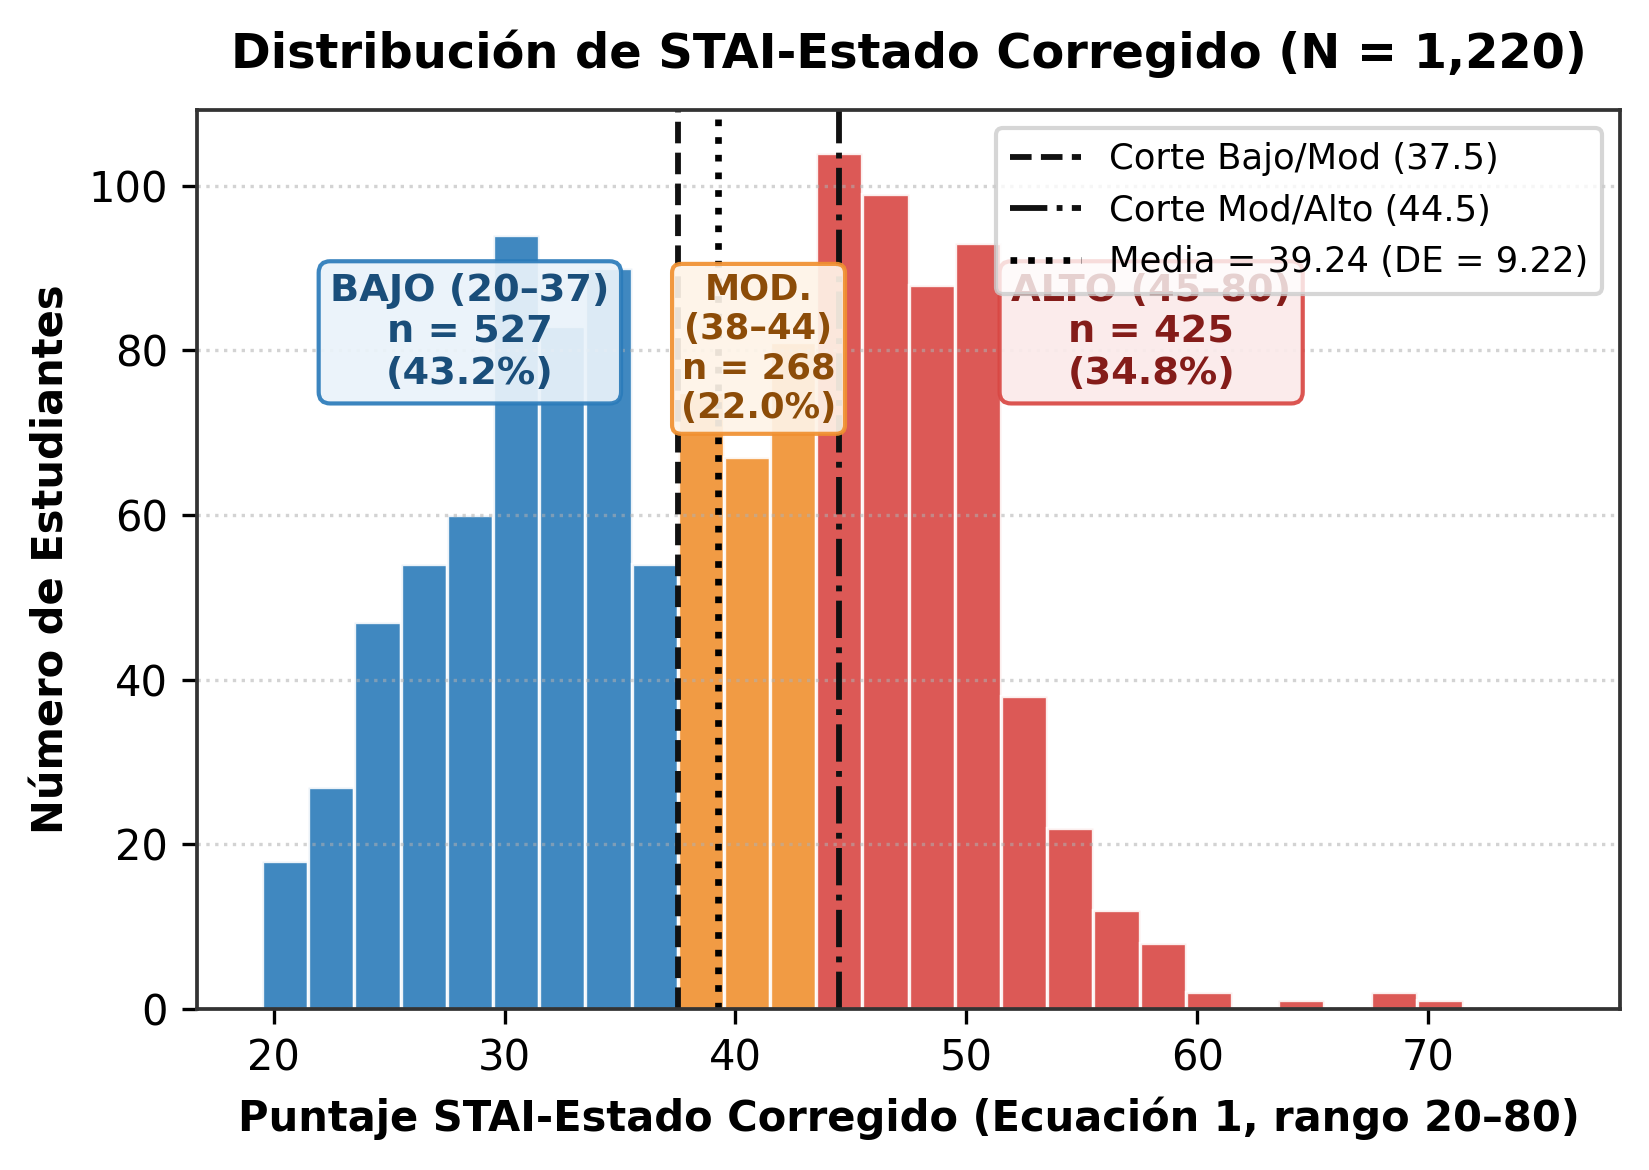

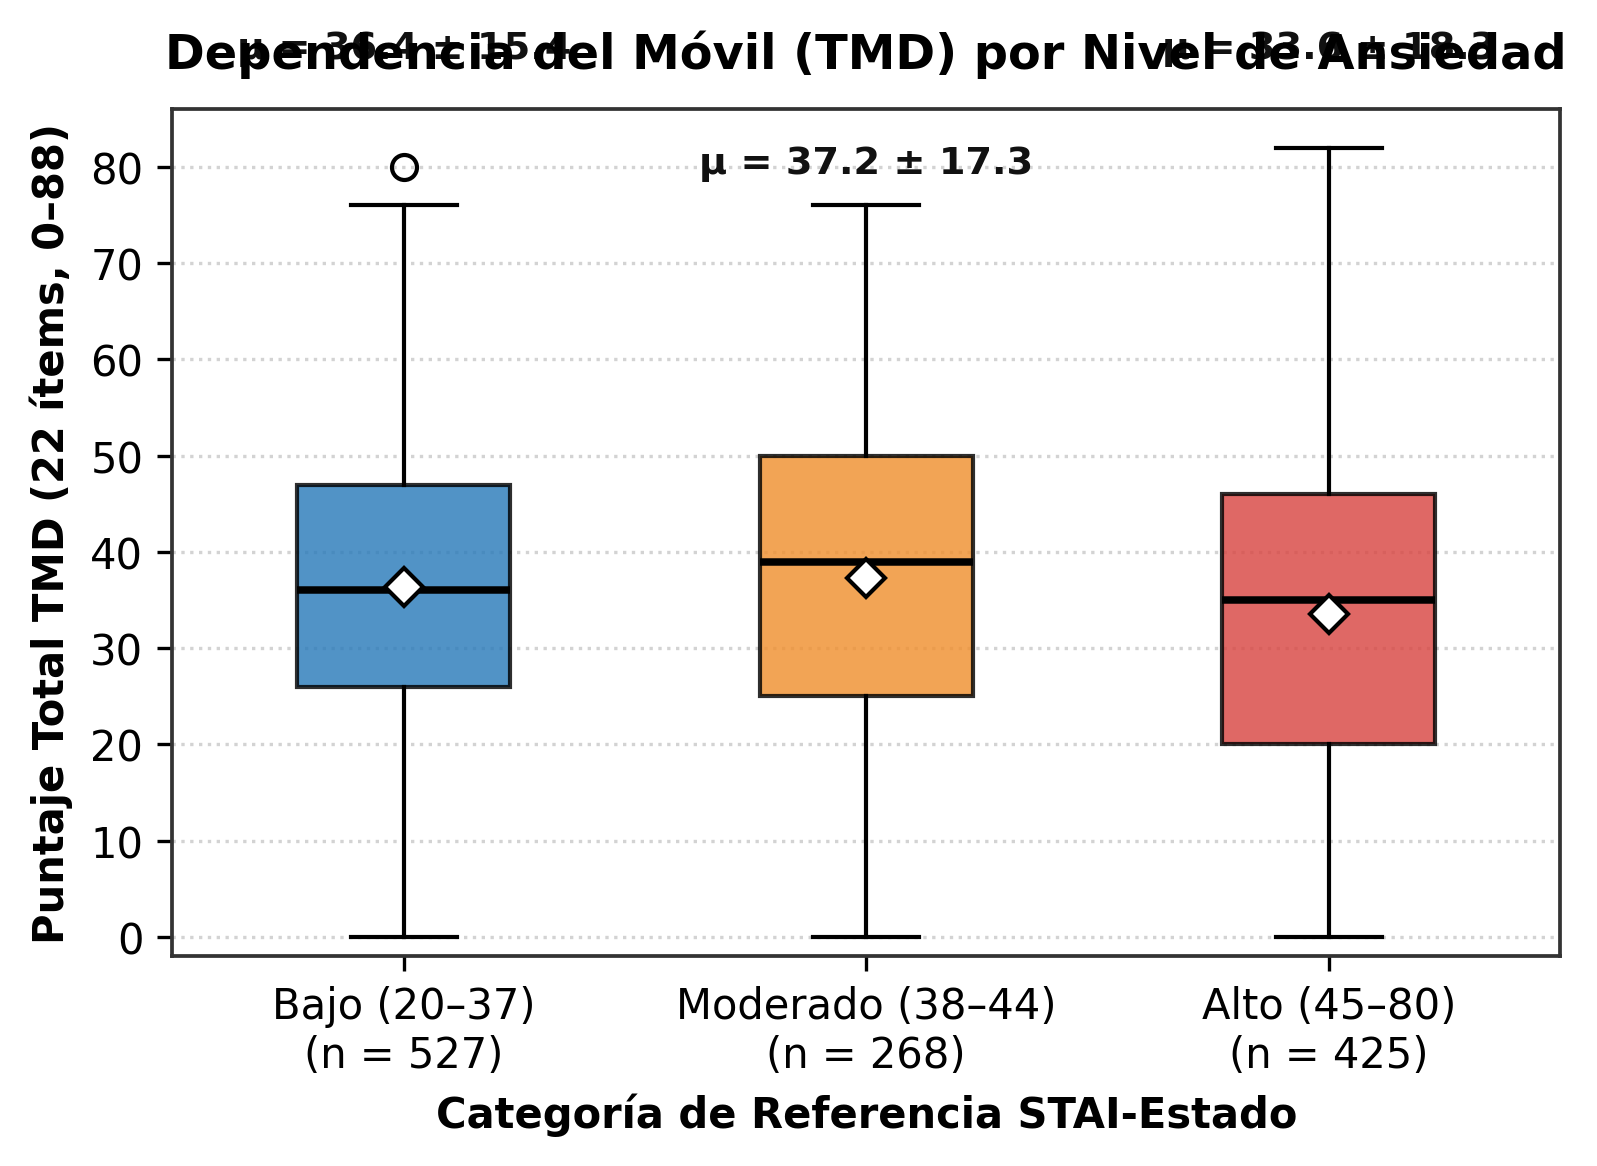

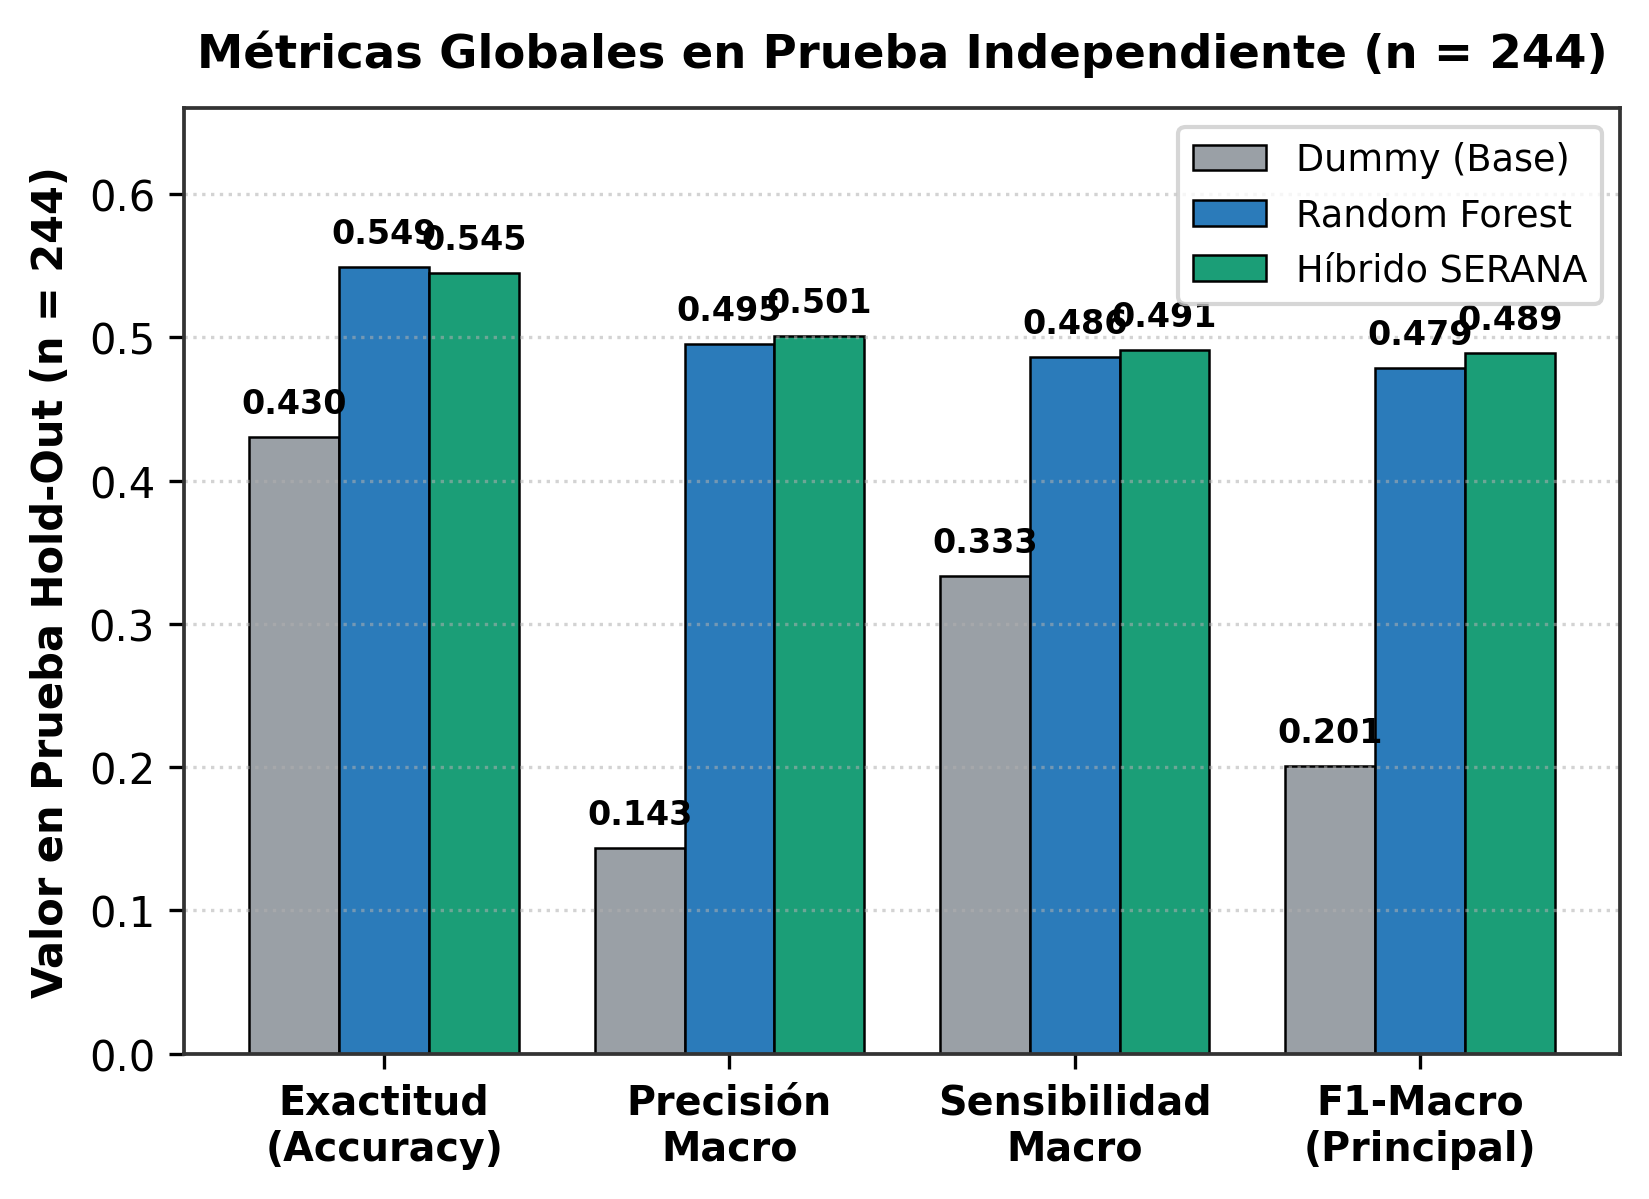

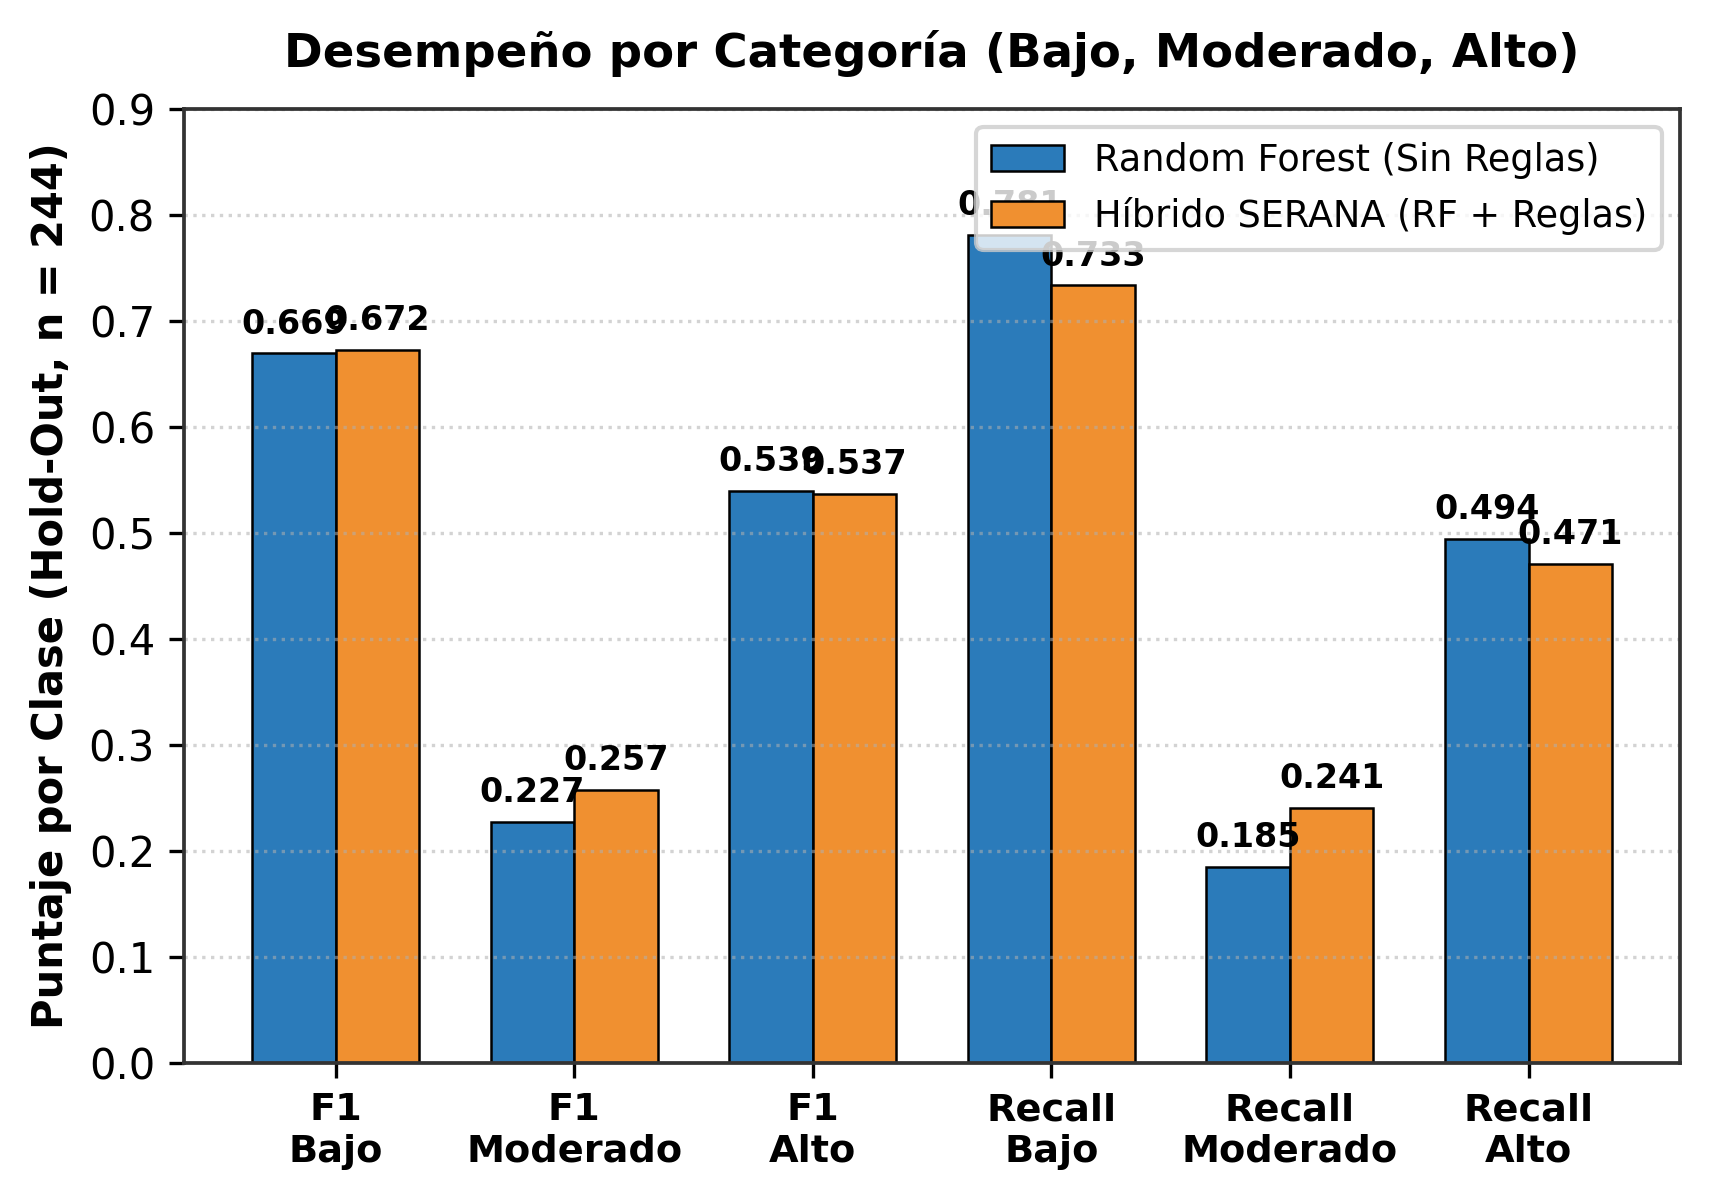

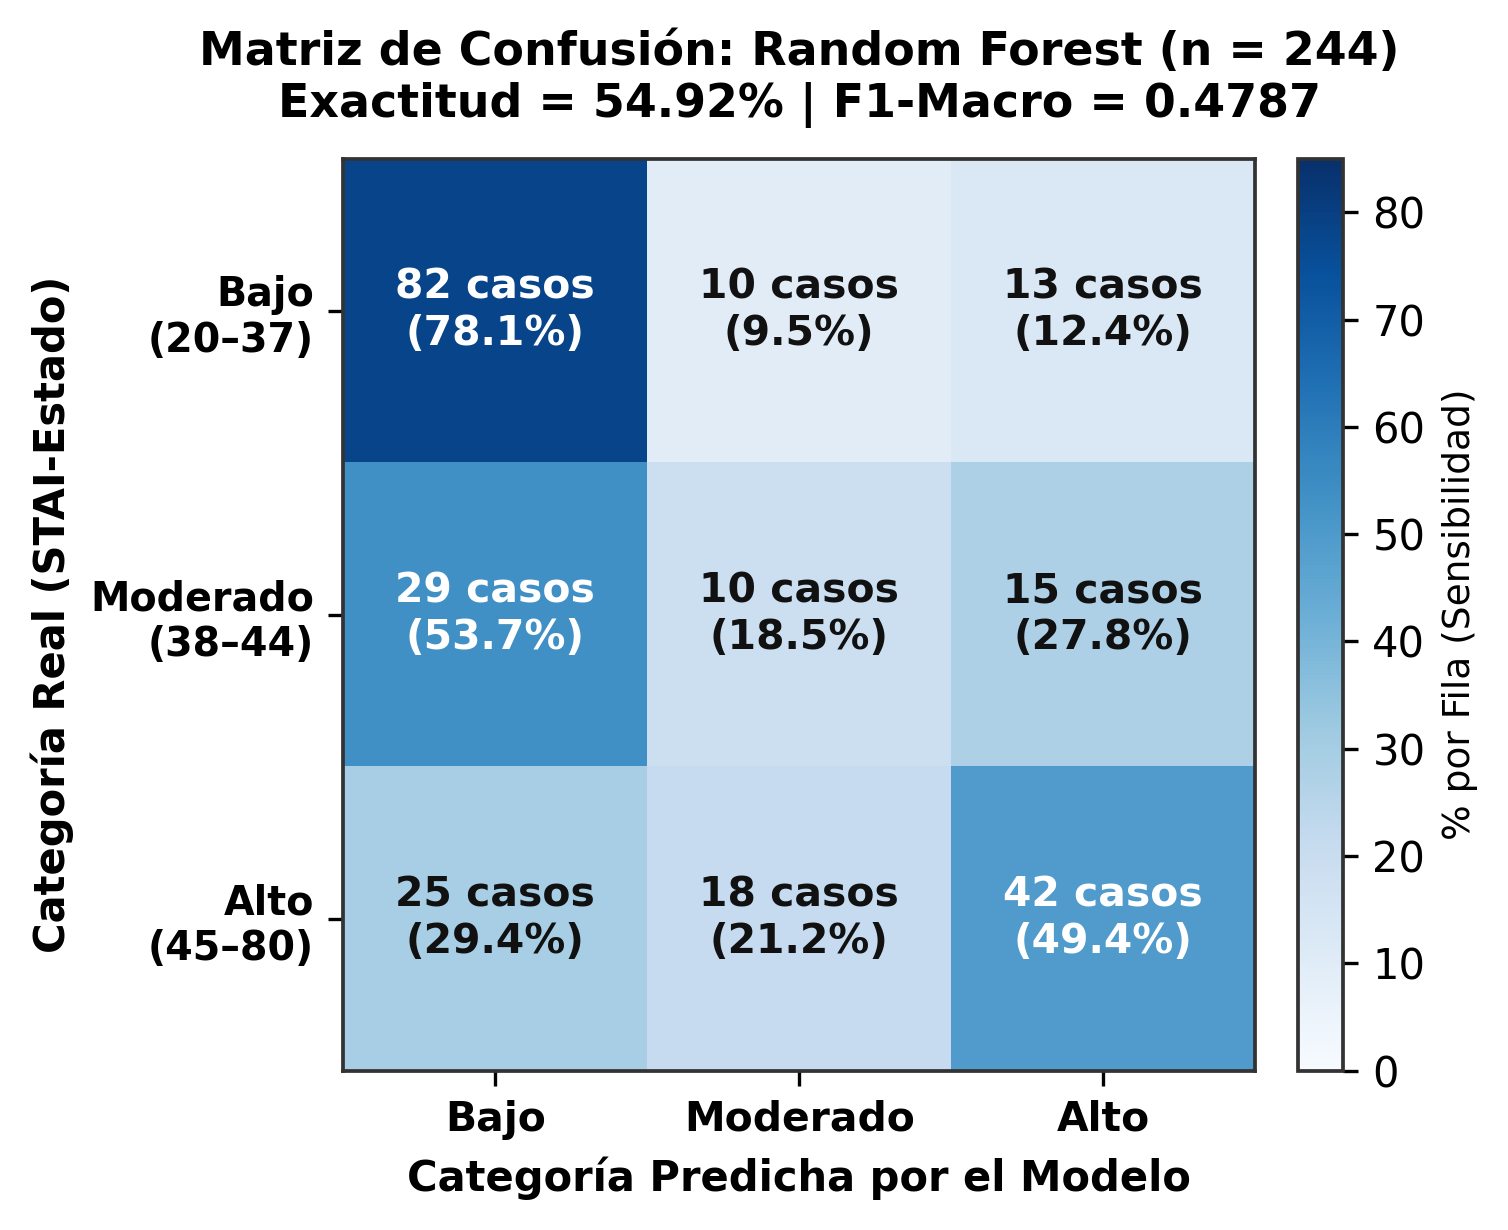

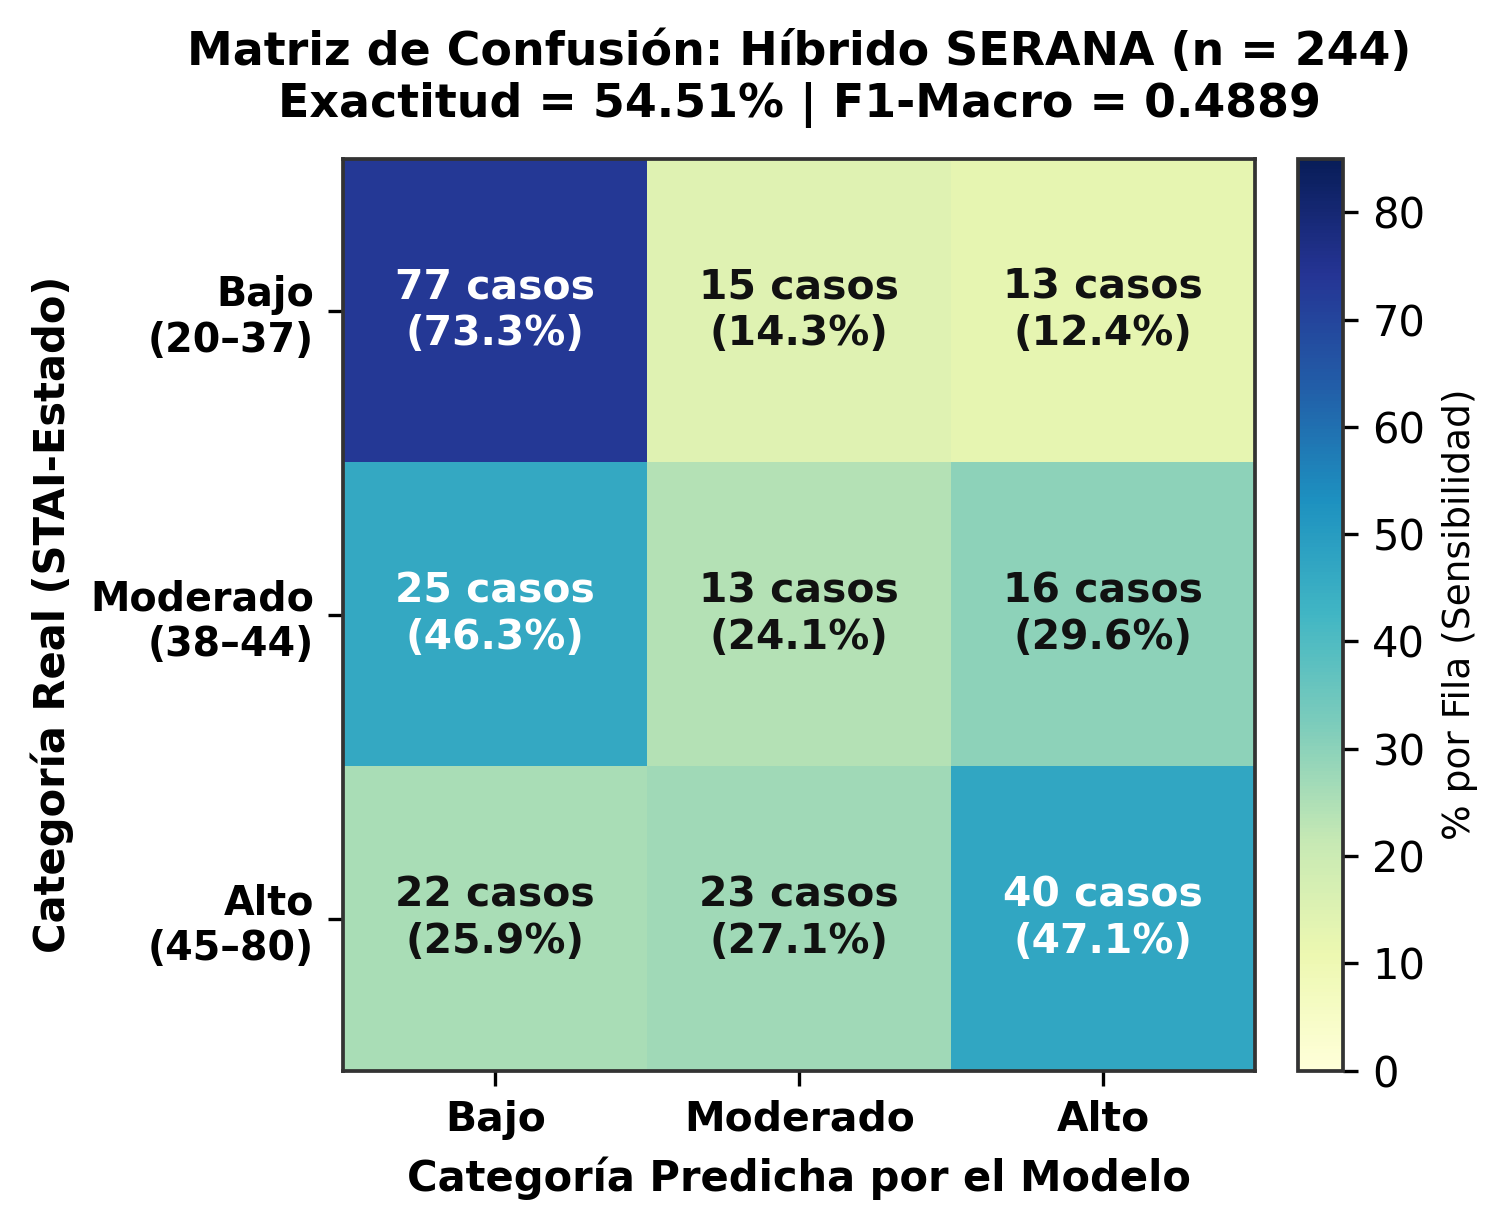

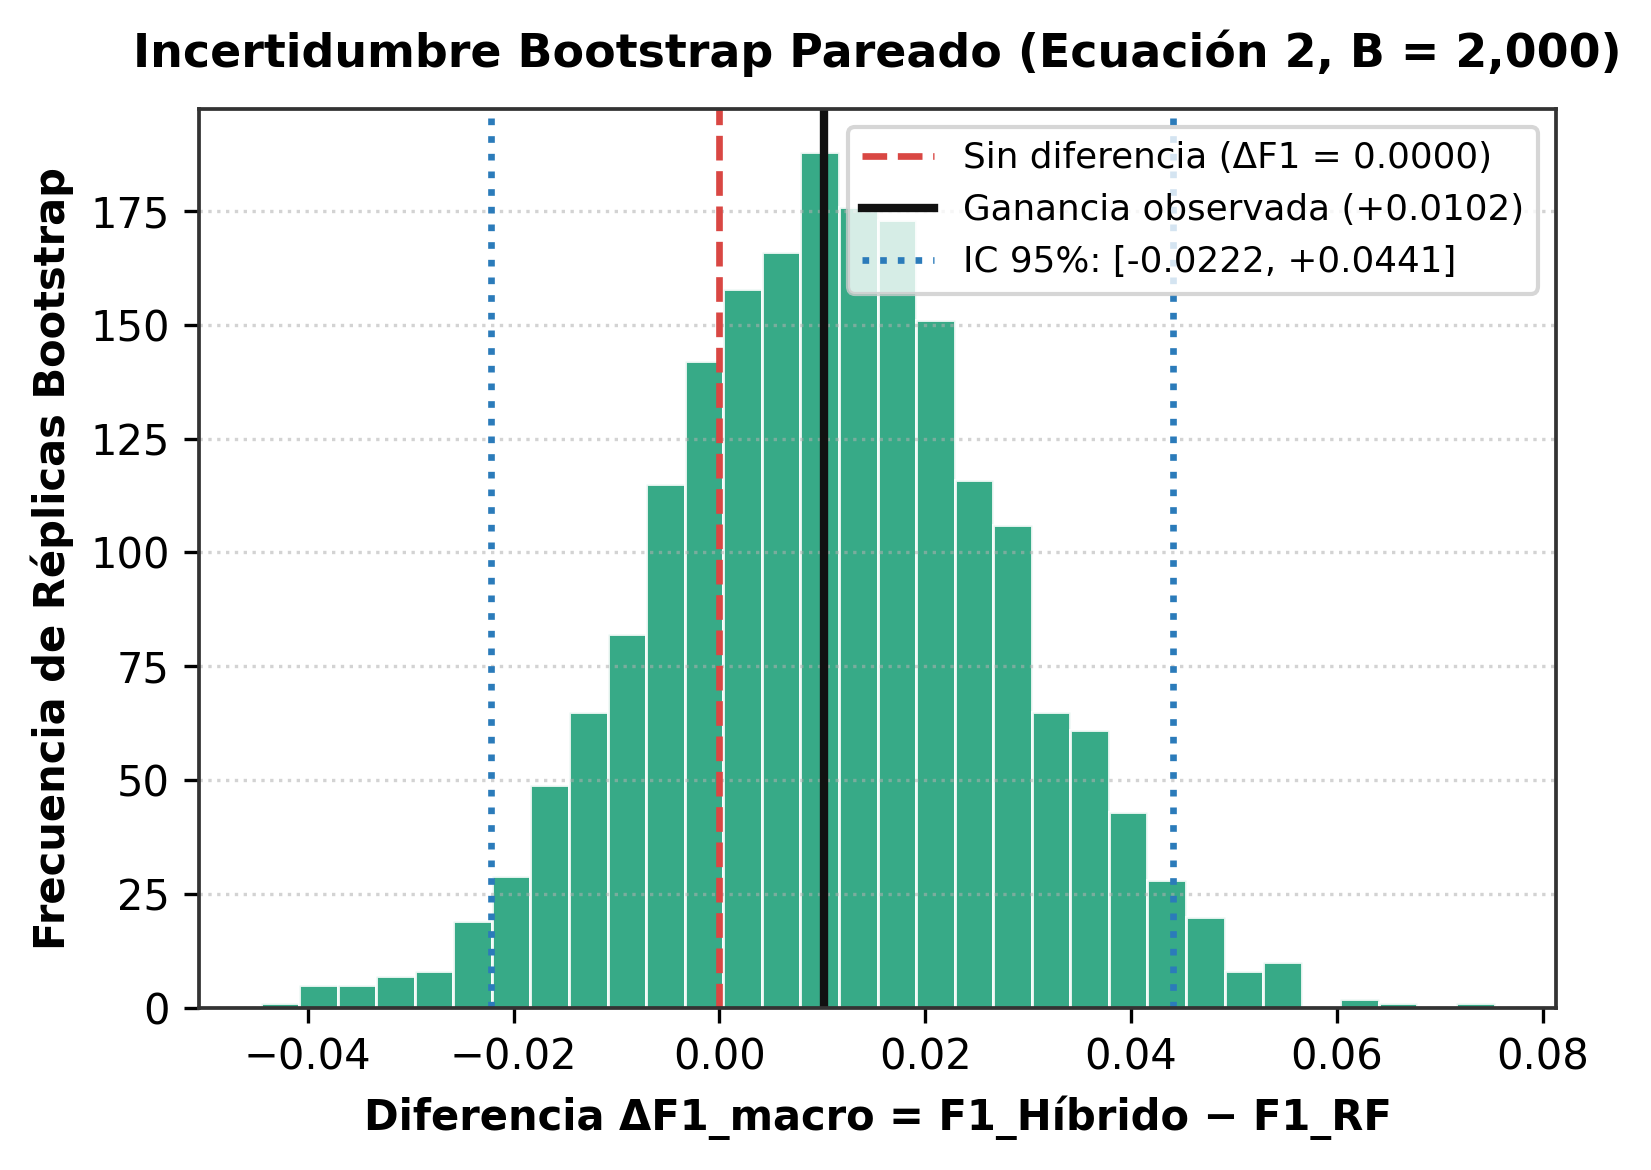

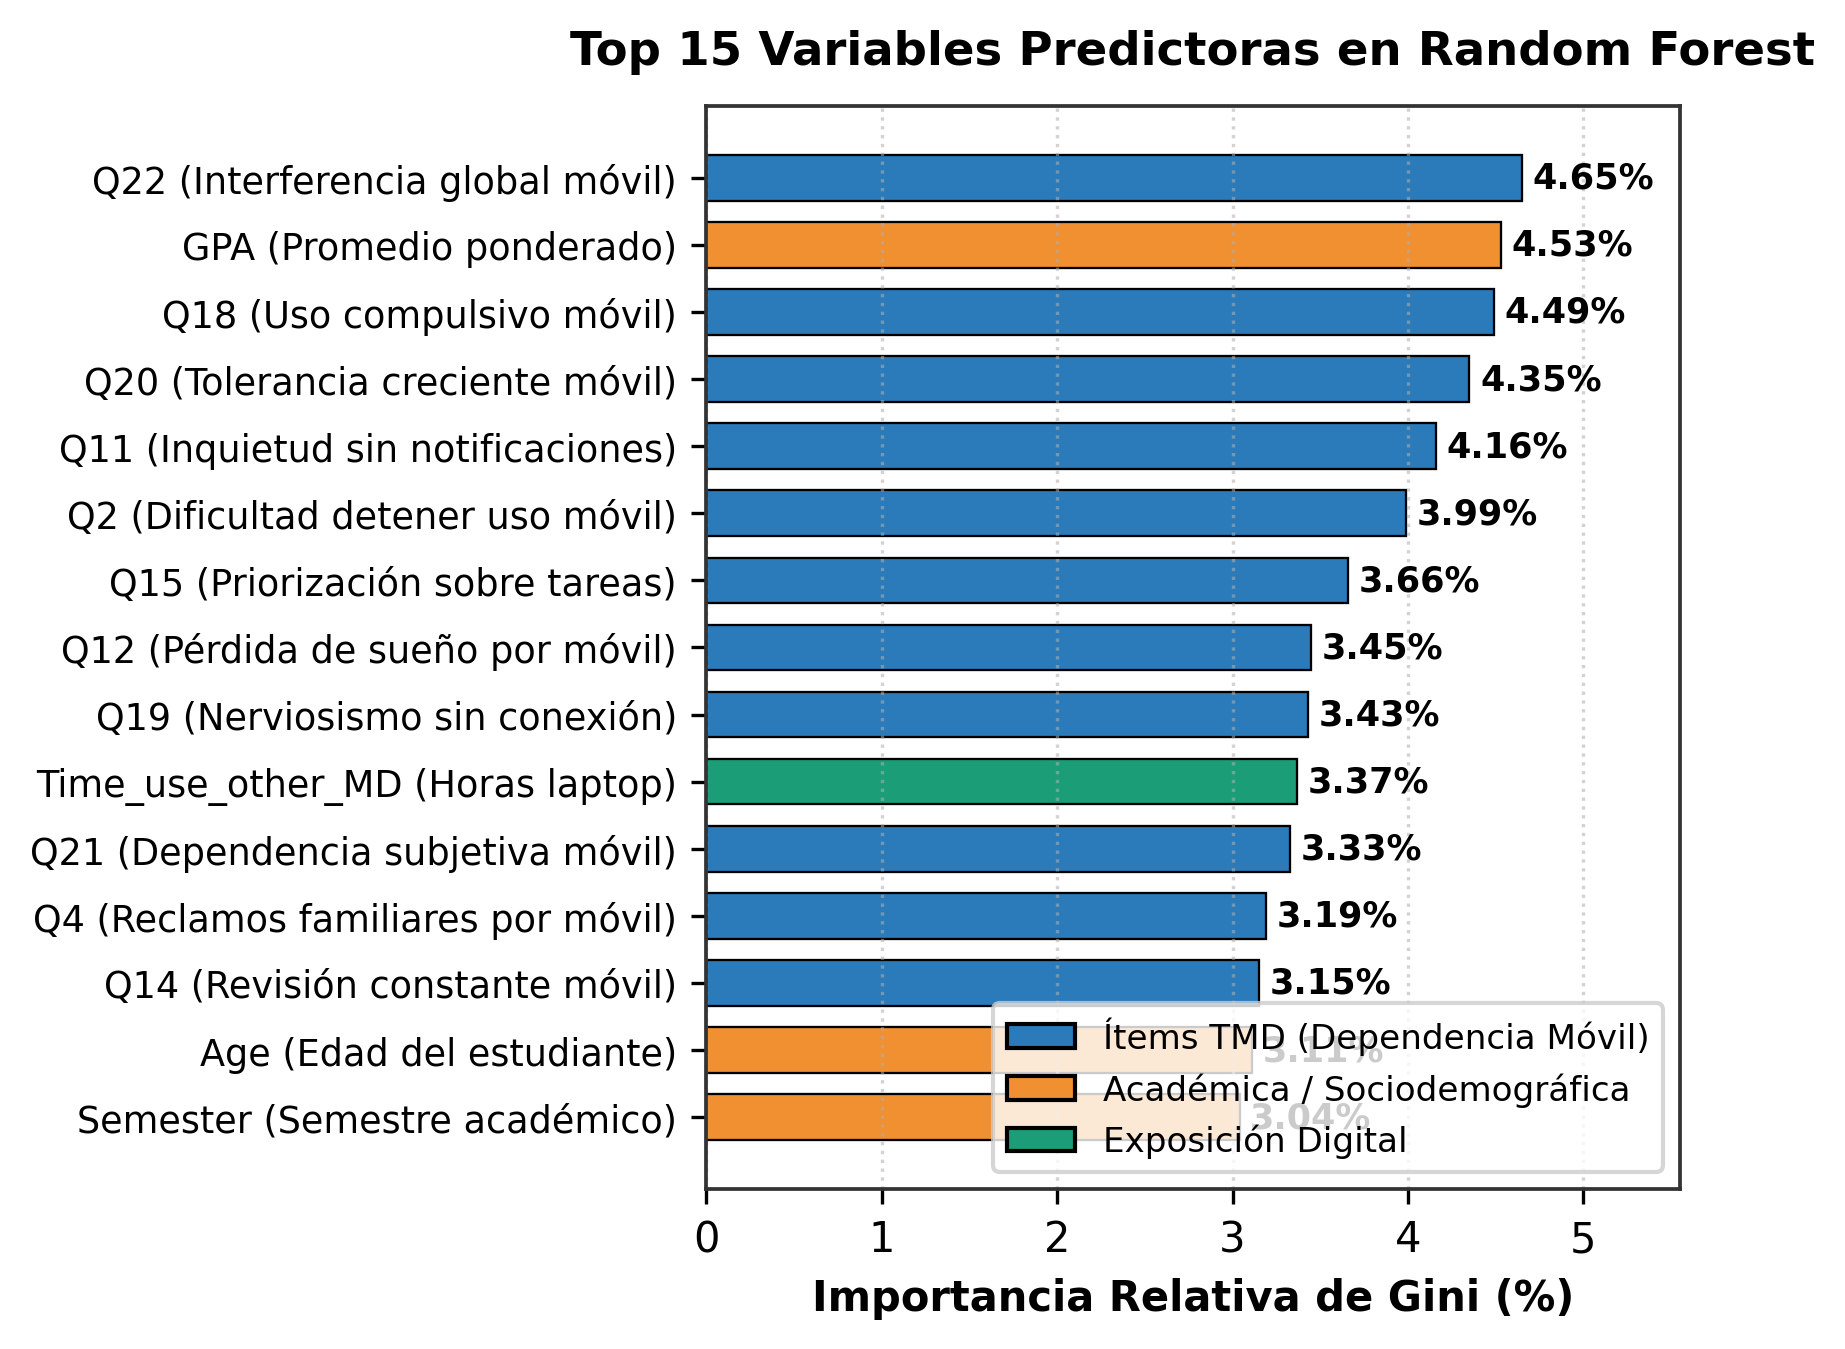

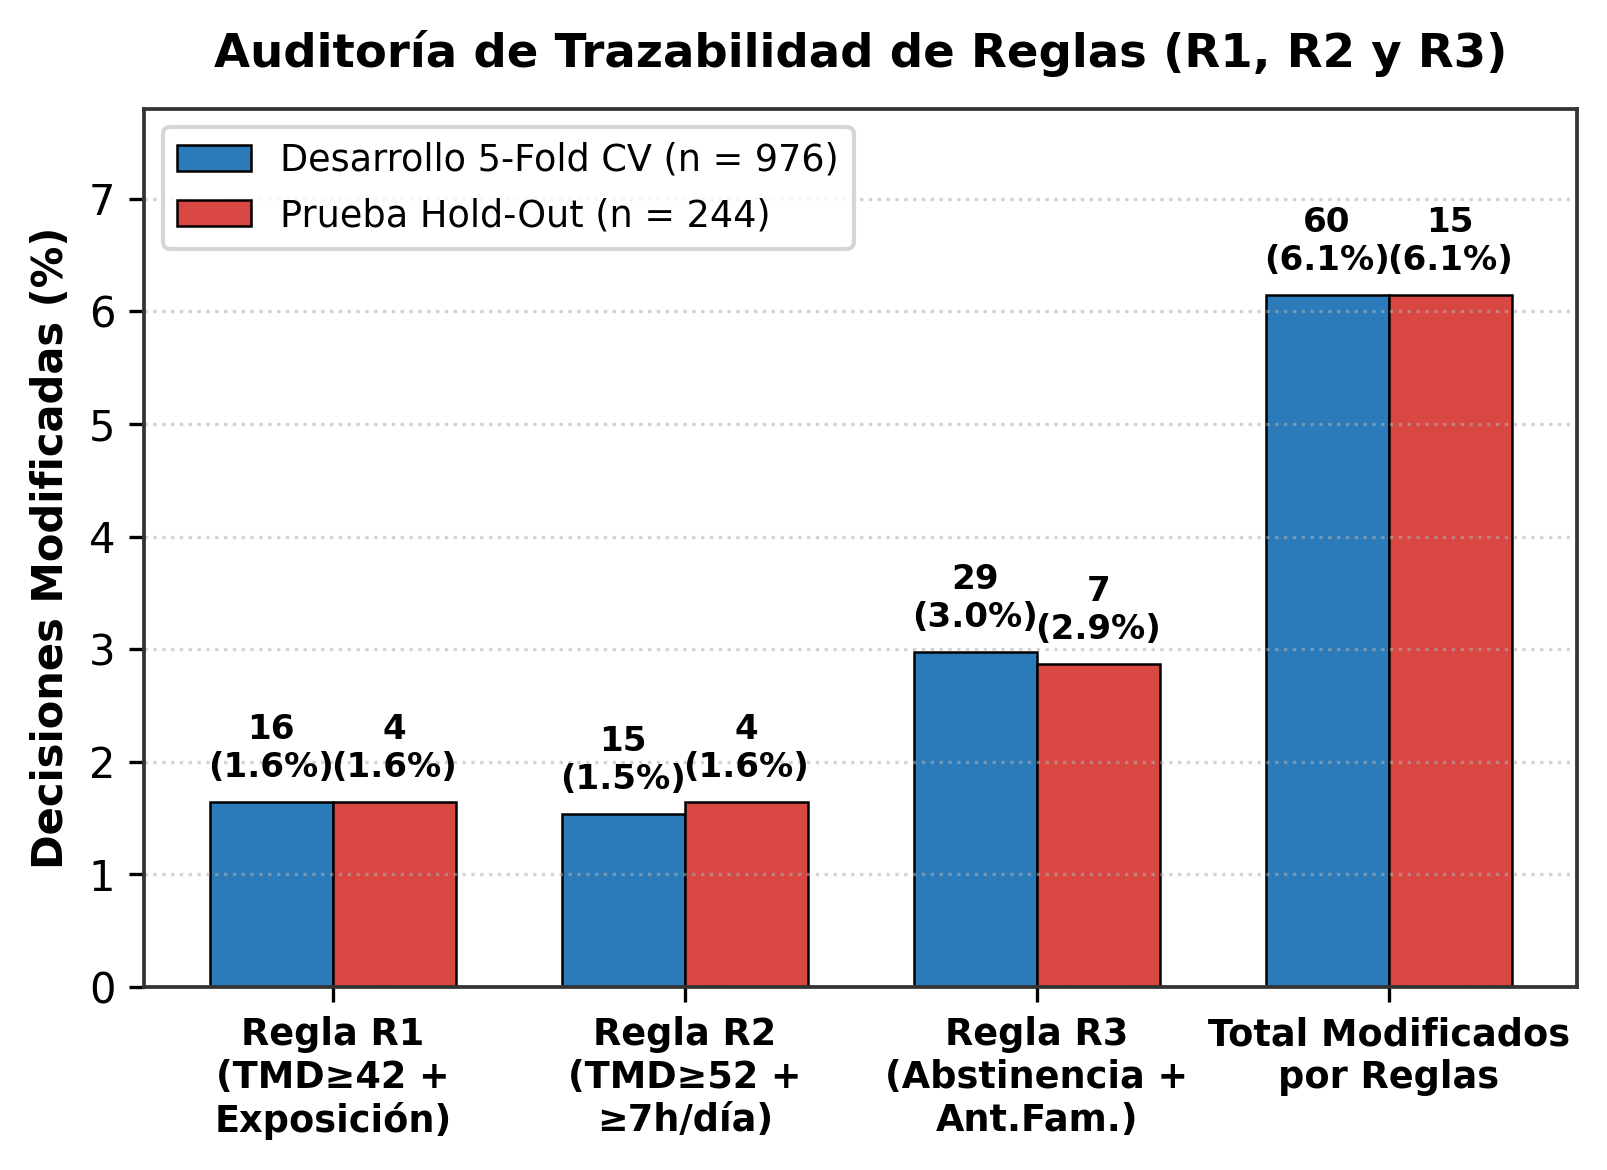

In [5]:
# ==============================================================================
# 8. GENERACIÓN DINÁMICA DE LAS 9 FIGURAS CIENTÍFICAS DEL ARTÍCULO (1 POR 1)
# (Cifras 100% dinámicas derivadas de predicciones reales sin datos hardcodeados)
# ==============================================================================
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, precision_score, recall_score

os.makedirs('figuras_paper', exist_ok=True)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.9

# Asegurar variables de conveniencia para gráficos
stai_vals = df['STAI_Estado_Puntaje_Corregido']
target_cats = df['risk_level']
tmd_totals = X[TMD_COLS].sum(axis=1)

# --- FIGURA 1: Histograma individual de STAI-Estado Corregido (Ecuación 1) ---
fig, ax = plt.subplots(figsize=(5.6, 4.0), dpi=150)
bins = np.arange(19.5, 76.5, 2)
n_vals, bin_edges, patches = ax.hist(stai_vals, bins=bins, edgecolor='white', linewidth=0.8, alpha=0.90)
for patch, x_left in zip(patches, bin_edges[:-1]):
    center = x_left + 1.0
    patch.set_facecolor('#2b7bba' if center <= 37 else ('#f09030' if center <= 44 else '#d94743'))
ax.axvline(37.5, color='#111111', linestyle='--', linewidth=1.4, label='Corte Bajo/Mod (37.5)')
ax.axvline(44.5, color='#111111', linestyle='-.', linewidth=1.4, label='Corte Mod/Alto (44.5)')
ax.axvline(stai_vals.mean(), color='#000000', linestyle=':', linewidth=1.6,
           label=f"Media = {stai_vals.mean():.2f} (DE = {stai_vals.std():.2f})")
ax.set_title('Figura 1: Distribución de STAI-Estado Corregido (N = 1,220)', fontweight='bold')
ax.set_xlabel('Puntaje STAI-Estado Corregido (Ecuación 1, rango 20–80)')
ax.set_ylabel('Número de Estudiantes')
ax.legend(loc='upper right', fontsize=8.5)
ax.grid(axis='y', linestyle=':', alpha=0.55)
plt.tight_layout()
plt.savefig('figuras_paper/fig1_histograma_stai_estado.png', dpi=300)
plt.show()

# --- FIGURA 2: Boxplot individual de TMD según Categoría de STAI-Estado ---
fig, ax = plt.subplots(figsize=(5.4, 4.0), dpi=150)
data_tmd = [tmd_totals[target_cats == c].values for c in [0, 1, 2]]
counts_cats = [len(d) for d in data_tmd]
bp = ax.boxplot(data_tmd, tick_labels=[f'Bajo (20–37)\n(n = {counts_cats[0]})', f'Moderado (38–44)\n(n = {counts_cats[1]})', f'Alto (45–80)\n(n = {counts_cats[2]})'],
                patch_artist=True, widths=0.46, showmeans=True)
for patch, col in zip(bp['boxes'], ['#2b7bba', '#f09030', '#d94743']):
    patch.set_facecolor(col)
    patch.set_alpha(0.82)
ax.set_title('Figura 2: Dependencia del Móvil (TMD) por Nivel de Ansiedad', fontweight='bold')
ax.set_xlabel('Categoría de Referencia STAI-Estado')
ax.set_ylabel('Puntaje Total TMD (22 ítems, 0–88)')
ax.grid(axis='y', linestyle=':', alpha=0.55)
plt.tight_layout()
plt.savefig('figuras_paper/fig2_boxplot_tmd_por_ansiedad.png', dpi=300)
plt.show()

# --- FIGURA 3: Métricas Globales en Prueba Independiente Hold-Out (n = 244) ---
fig, ax = plt.subplots(figsize=(5.6, 4.1), dpi=150)
metrics_names = ['Exactitud\n(Accuracy)', 'Precisión\nMacro', 'Sensibilidad\nMacro', 'F1-Macro\n(Principal)']
x = np.arange(len(metrics_names))
w = 0.26
dum_vals = [accuracy_score(y_test, test_pred_dum), precision_score(y_test, test_pred_dum, average='macro', zero_division=0), recall_score(y_test, test_pred_dum, average='macro', zero_division=0), f1_score(y_test, test_pred_dum, average='macro')]
rf_vals  = [accuracy_score(y_test, test_pred_rf), precision_score(y_test, test_pred_rf, average='macro', zero_division=0), recall_score(y_test, test_pred_rf, average='macro', zero_division=0), f1_score(y_test, test_pred_rf, average='macro')]
hyb_vals = [accuracy_score(y_test, test_pred_hyb), precision_score(y_test, test_pred_hyb, average='macro', zero_division=0), recall_score(y_test, test_pred_hyb, average='macro', zero_division=0), f1_score(y_test, test_pred_hyb, average='macro')]

ax.bar(x - w, dum_vals, w, label='Dummy (Base)', color='#9aa0a6', edgecolor='black')
ax.bar(x,     rf_vals,  w, label='Random Forest', color='#2b7bba', edgecolor='black')
ax.bar(x + w, hyb_vals, w, label='Híbrido SERANA', color='#1b9e77', edgecolor='black')
ax.set_ylim(0, 0.68)
ax.set_xticks(x)
ax.set_xticklabels(metrics_names)
ax.set_ylabel('Valor en Prueba Hold-Out (n = 244)')
ax.set_title('Figura 3: Métricas Globales en Prueba Independiente (n = 244)', fontweight='bold')
ax.legend(loc='upper right', fontsize=8.8)
ax.grid(axis='y', linestyle=':', alpha=0.55)
plt.tight_layout()
plt.savefig('figuras_paper/fig3_metricas_globales_holdout.png', dpi=300)
plt.show()

# --- FIGURA 4: Desempeño F1 y Sensibilidad por Categoría en Hold-Out (n = 244) ---
fig, ax = plt.subplots(figsize=(5.8, 4.1), dpi=150)
class_labels = ['F1\nBajo', 'F1\nModerado', 'F1\nAlto', 'Recall\nBajo', 'Recall\nModerado', 'Recall\nAlto']
x2 = np.arange(len(class_labels))
w2 = 0.35
rf_per_class = [
    f1_score(y_test, test_pred_rf, labels=[0], average='macro', zero_division=0),
    f1_score(y_test, test_pred_rf, labels=[1], average='macro', zero_division=0),
    f1_score(y_test, test_pred_rf, labels=[2], average='macro', zero_division=0),
    recall_score(y_test, test_pred_rf, labels=[0], average='macro', zero_division=0),
    recall_score(y_test, test_pred_rf, labels=[1], average='macro', zero_division=0),
    recall_score(y_test, test_pred_rf, labels=[2], average='macro', zero_division=0)
]
hyb_per_class = [
    f1_score(y_test, test_pred_hyb, labels=[0], average='macro', zero_division=0),
    f1_score(y_test, test_pred_hyb, labels=[1], average='macro', zero_division=0),
    f1_score(y_test, test_pred_hyb, labels=[2], average='macro', zero_division=0),
    recall_score(y_test, test_pred_hyb, labels=[0], average='macro', zero_division=0),
    recall_score(y_test, test_pred_hyb, labels=[1], average='macro', zero_division=0),
    recall_score(y_test, test_pred_hyb, labels=[2], average='macro', zero_division=0)
]
ax.bar(x2 - w2/2, rf_per_class,  w2, label='Random Forest (Sin Reglas)', color='#2b7bba', edgecolor='black')
ax.bar(x2 + w2/2, hyb_per_class, w2, label='Híbrido SERANA (RF + Reglas)', color='#f09030', edgecolor='black')
ax.set_ylim(0, 0.90)
ax.set_xticks(x2)
ax.set_xticklabels(class_labels)
ax.set_ylabel('Puntaje por Clase (Hold-Out, n = 244)')
ax.set_title('Figura 4: Desempeño por Categoría (Bajo, Moderado, Alto)', fontweight='bold')
ax.legend(loc='upper right', fontsize=8.8)
ax.grid(axis='y', linestyle=':', alpha=0.55)
plt.tight_layout()
plt.savefig('figuras_paper/fig4_desempeno_por_clase_holdout.png', dpi=300)
plt.show()

# --- FIGURA 5: Matriz de Confusión Dinámica - Random Forest (n = 244) ---
fig, ax = plt.subplots(figsize=(5.0, 4.2), dpi=150)
cm_rf_arr = confusion_matrix(y_test, test_pred_rf)
perc_rf = cm_rf_arr / cm_rf_arr.sum(axis=1, keepdims=True) * 100.0
im = ax.imshow(perc_rf, cmap='Blues', vmin=0, vmax=85)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='% por Fila (Sensibilidad)')
ax.set_xticks([0, 1, 2]); ax.set_xticklabels(['Bajo', 'Moderado', 'Alto'])
ax.set_yticks([0, 1, 2]); ax.set_yticklabels(['Bajo (20–37)', 'Moderado (38–44)', 'Alto (45–80)'])
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{cm_rf_arr[i, j]} casos\n({perc_rf[i, j]:.1f}%)', ha='center', va='center',
                color='white' if perc_rf[i, j] > 45 else '#111111', fontweight='bold')
ax.set_title(f'Figura 5: Matriz de Confusión Random Forest (n = 244 | Acc = {accuracy_score(y_test, test_pred_rf)*100:.2f}%)', fontweight='bold')
ax.set_xlabel('Categoría Predicha'); ax.set_ylabel('Categoría Real (STAI-Estado)')
plt.tight_layout()
plt.savefig('figuras_paper/fig5_matriz_confusion_rf.png', dpi=300)
plt.show()

# --- FIGURA 6: Matriz de Confusión Dinámica - Híbrido SERANA (n = 244) ---
fig, ax = plt.subplots(figsize=(5.0, 4.2), dpi=150)
cm_hyb_arr = confusion_matrix(y_test, test_pred_hyb)
perc_hyb = cm_hyb_arr / cm_hyb_arr.sum(axis=1, keepdims=True) * 100.0
im2 = ax.imshow(perc_hyb, cmap='YlGnBu', vmin=0, vmax=85)
fig.colorbar(im2, ax=ax, fraction=0.046, pad=0.04, label='% por Fila (Sensibilidad)')
ax.set_xticks([0, 1, 2]); ax.set_xticklabels(['Bajo', 'Moderado', 'Alto'])
ax.set_yticks([0, 1, 2]); ax.set_yticklabels(['Bajo (20–37)', 'Moderado (38–44)', 'Alto (45–80)'])
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{cm_hyb_arr[i, j]} casos\n({perc_hyb[i, j]:.1f}%)', ha='center', va='center',
                color='white' if perc_hyb[i, j] > 45 else '#111111', fontweight='bold')
ax.set_title(f'Figura 6: Matriz de Confusión Híbrido SERANA (n = 244 | Acc = {accuracy_score(y_test, test_pred_hyb)*100:.2f}%)', fontweight='bold')
ax.set_xlabel('Categoría Predicha'); ax.set_ylabel('Categoría Real (STAI-Estado)')
plt.tight_layout()
plt.savefig('figuras_paper/fig6_matriz_confusion_hibrido.png', dpi=300)
plt.show()

# --- FIGURA 7: Bootstrap Pareado Individual (Ecuación 2, B = 2,000) ---
fig, ax = plt.subplots(figsize=(5.5, 4.0), dpi=150)
diffs = np.array(boot_deltas_test)
ci_low = float(np.percentile(diffs, 2.5))
ci_high = float(np.percentile(diffs, 97.5))
ax.hist(diffs, bins=32, color='#1b9e77', edgecolor='white', alpha=0.88)
ax.axvline(0.0, color='#d94743', linestyle='--', linewidth=1.6, label='Sin diferencia (ΔF1 = 0.0000)')
ax.axvline(delta_test_obs, color='#111111', linestyle='-', linewidth=2.0, label=f'Ganancia observada ({delta_test_obs:+.4f})')
ax.axvline(ci_low, color='#2b7bba', linestyle=':', linewidth=1.6, label=f'IC 95%: [{ci_low:+.4f}, {ci_high:+.4f}]')
ax.axvline(ci_high, color='#2b7bba', linestyle=':', linewidth=1.6)
ax.set_title('Figura 7: Incertidumbre Bootstrap Pareado (Ecuación 2, B = 2,000)', fontweight='bold')
ax.set_xlabel('Diferencia ΔF1_macro = F1_Híbrido − F1_RF')
ax.set_ylabel('Frecuencia de Réplicas Bootstrap')
ax.legend(loc='upper right', fontsize=8.6)
ax.grid(axis='y', linestyle=':', alpha=0.55)
plt.tight_layout()
plt.savefig('figuras_paper/fig7_bootstrap_pareado_delta_f1.png', dpi=300)
plt.show()

# --- FIGURA 8: Top 15 Variables Predictoras según Importancia Gini ---
fig, ax = plt.subplots(figsize=(5.8, 4.6), dpi=150)
top15 = feature_imp_df.head(15).iloc[::-1]
ax.barh(top15['Característica'], top15['Importancia'] * 100.0, color='#2b7bba', edgecolor='black', height=0.68)
ax.set_xlabel('Importancia Relativa de Gini (%)')
ax.set_title('Figura 8: Top 15 Variables Predictoras en Random Forest', fontweight='bold')
ax.grid(axis='x', linestyle=':', alpha=0.55)
plt.tight_layout()
plt.savefig('figuras_paper/fig8_importancia_variables_gini.png', dpi=300)
plt.show()

# --- FIGURA 9: Auditoría Dinámica de Activación de Reglas (R1, R2 y R3) ---
fig, ax = plt.subplots(figsize=(5.5, 4.0), dpi=150)
r1_dev  = sum(1 for r in oof_reglas if 'R1' in r)
r2_dev  = sum(1 for r in oof_reglas if 'R2' in r)
r3_dev  = sum(1 for r in oof_reglas if 'R3' in r)
tot_dev = sum(1 for r in oof_reglas if r != 'NINGUNA')

r1_test  = sum(1 for r in test_reglas if 'R1' in r)
r2_test  = sum(1 for r in test_reglas if 'R2' in r)
r3_test  = sum(1 for r in test_reglas if 'R3' in r)
tot_test = sum(1 for r in test_reglas if r != 'NINGUNA')

rule_labels = ['Regla R1\n(Transición Mod.)', 'Regla R2\n(Escalamiento Alto)', 'Regla R3\n(Atenuación Bajo)', 'Total Modificados\npor Reglas']
xr = np.arange(len(rule_labels))
wr = 0.35
ax.bar(xr - wr/2, [r1_dev/len(X_dev)*100, r2_dev/len(X_dev)*100, r3_dev/len(X_dev)*100, tot_dev/len(X_dev)*100], wr, label=f'Desarrollo 5-Fold CV (n = {len(X_dev)})', color='#2b7bba', edgecolor='black')
ax.bar(xr + wr/2, [r1_test/len(X_test)*100, r2_test/len(X_test)*100, r3_test/len(X_test)*100, tot_test/len(X_test)*100], wr, label=f'Prueba Hold-Out (n = {len(X_test)})', color='#d94743', edgecolor='black')
ax.set_ylim(0, max(tot_dev/len(X_dev)*100, tot_test/len(X_test)*100) * 1.35)
ax.set_xticks(xr); ax.set_xticklabels(rule_labels)
ax.set_ylabel('Decisiones Modificadas (%)')
ax.set_title('Figura 9: Auditoría de Trazabilidad de Reglas (R1, R2 y R3)', fontweight='bold')
ax.legend(loc='upper left', fontsize=8.8)
ax.grid(axis='y', linestyle=':', alpha=0.55)
plt.tight_layout()
plt.savefig('figuras_paper/fig9_auditoria_reglas_r1_r3.png', dpi=300)
plt.show()

print('Las 9 figuras científicas han sido generadas y guardadas exitosamente en la carpeta figuras_paper/.')
